# pnmzad06

Notebook SageMath do zadania 6.


Importy i zmienne symboliczne:


In [5]:
from sage.arith.misc import *

x, u, n, i = var('x u n i')


Definicja funkcji g(x) = sin^2(x) oraz jawnej postaci calki Ig(x):


In [ ]:
g = symbolic_expression(sin(x)**2).function(x)
Ig = symbolic_expression(x/2 - sin(2*x)/4).function(x)

print('g(x) =', g(x))
print('Ig(x) =', Ig(x))
print('D(Ig)(x) - g(x) =', (diff(Ig(x), x) - g(x)).full_simplify())


g(x) = sin(x)^2
Ig(x) = 1/2*x - 1/4*sin(2*x)
D(Ig)(x) - g(x) = 0


Wykres funkcji g(x) i jej calki Ig(x) w przedziale [1, 10] z zakresem osi Y [0, 6]:


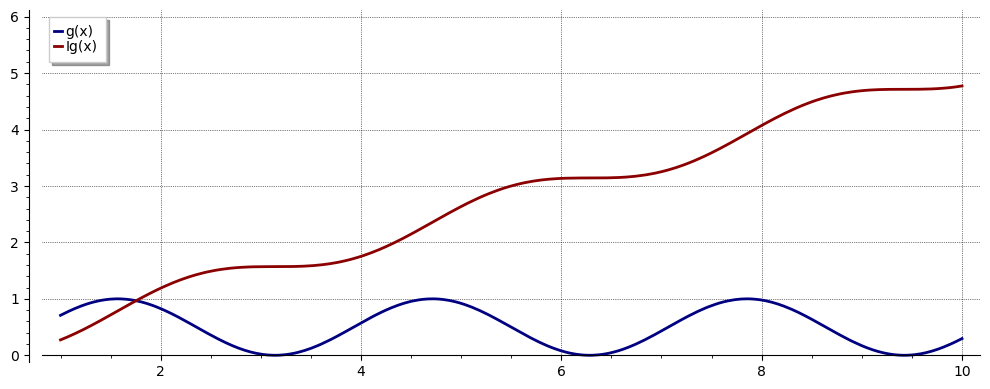

In [7]:
p = plot(g(x), (x, 1, 10), color='navy', thickness=2, legend_label='g(x)')
p += plot(Ig(x), (x, 1, 10), color='darkred', thickness=2, legend_label='Ig(x)')
show(p, ymin=0, ymax=6, figsize=[10, 4], gridlines=True, legend_loc='upper left')


Definicja sumy Riemanna, funkcji Sg(x, n) oraz granicy Lg(x):


In [8]:
def rsum(f, x_value, n_value):
    dx = x_value / n_value
    i = var('i')
    return dx * sum(f(i * dx), i, 1, n_value)

Sg_expr = rsum(g, x, n).full_simplify()
Lg_expr = limit(Sg_expr, n=oo).full_simplify()

print('Sg(x, n) =', Sg_expr)
print('Lg(x) =', Lg_expr)
print('Ig(x) =', Ig(x))
print('Lg(x) == Ig(x):', bool((Lg_expr - Ig(x)).full_simplify() == 0))


Sg(x, n) = -1/4*(x*cos(x/n)*sin((n + 1)*arctan2(2*cos(x/n)*sin(x/n), -2*sin(x/n)^2 + 1)) - (2*n + 1)*x*sin(x/n) - x*cos((n + 1)*arctan2(2*cos(x/n)*sin(x/n), -2*sin(x/n)^2 + 1))*sin(x/n))/(n*sin(x/n))
Lg(x) = -1/2*cos(x)*sin(x) + 1/2*x
Ig(x) = 1/2*x - 1/4*sin(2*x)
Lg(x) == Ig(x): True


Numeryczna weryfikacja na wykresach dla n = 5, 10, 20, 80:


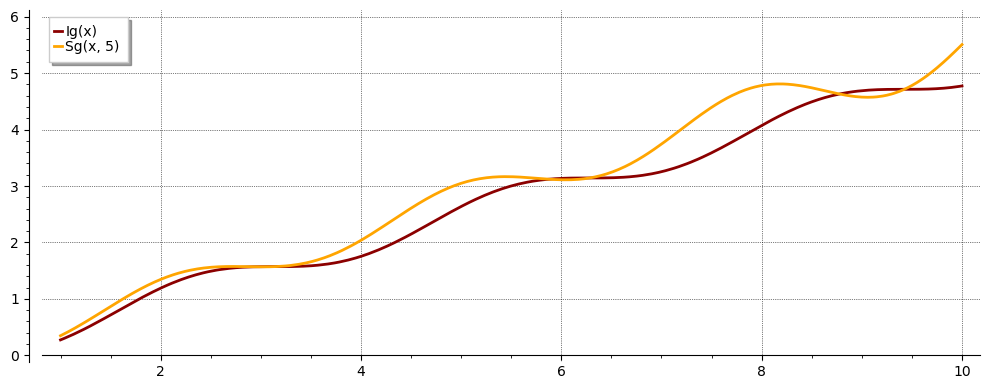

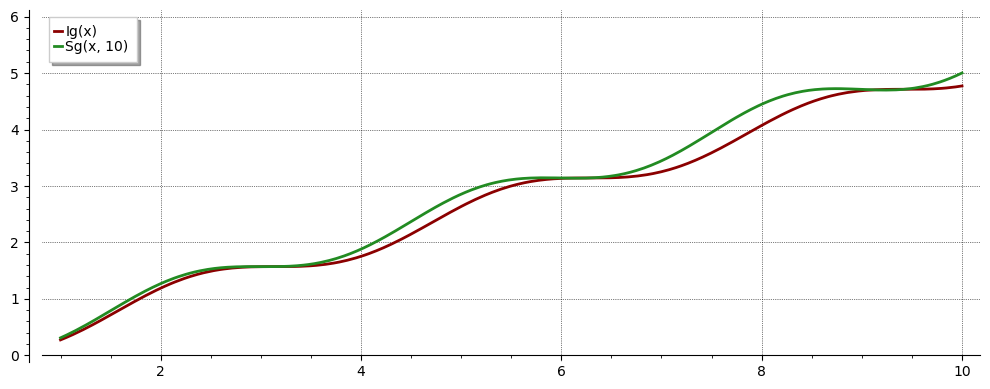

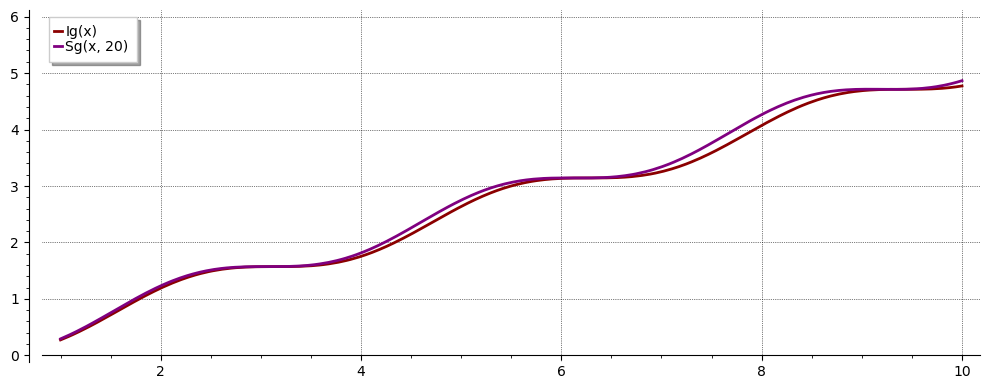

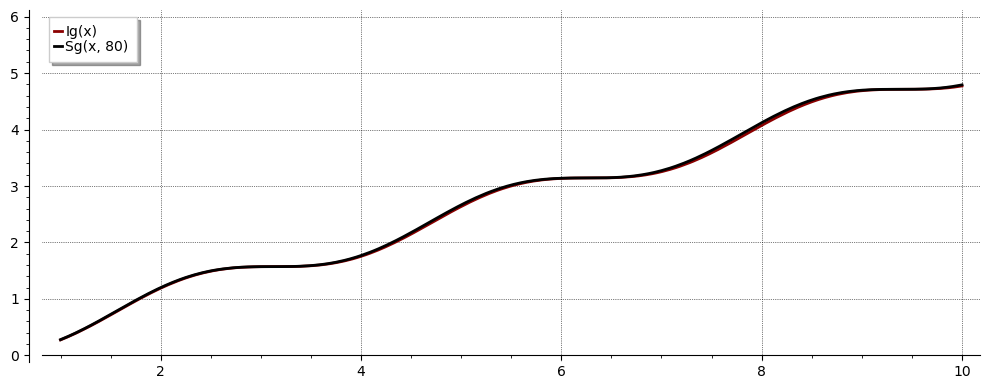

In [9]:
colors = ['orange', 'forestgreen', 'purple', 'black']

for parts, color in zip([5, 10, 20, 80], colors):
    plot_integral = plot(Ig(x), (x, 1, 10), color='darkred', thickness=2, legend_label='Ig(x)')
    plot_sum = plot(lambda xx: float(N(rsum(g, xx, parts))), (1, 10), color=color, thickness=2, plot_points=250, legend_label=f'Sg(x, {parts})')
    show(plot_integral + plot_sum, ymin=0, ymax=6, figsize=[10, 4], gridlines=True, legend_loc='upper left')


Dodatkowe porownanie wartosci numerycznych w kilku punktach:


In [10]:
sample_points = [1, 2, 5, 10]
for point in sample_points:
    exact_value = float(N(Ig(point)))
    approx_value = float(N(rsum(g, point, 80)))
    abs_error = abs(exact_value - approx_value)
    print(f'x = {point:>2}  Ig(x) = {exact_value:.10f}  Sg(x,80) = {approx_value:.10f}  blad = {abs_error:.3e}')


x =  1  Ig(x) = 0.2726756433  Sg(x,80) = 0.2771129421  blad = 4.437e-03
x =  2  Ig(x) = 1.1892006238  Sg(x,80) = 1.1994964780  blad = 1.030e-02
x =  5  Ig(x) = 2.6360052777  Sg(x,80) = 2.6645636340  blad = 2.856e-02
x = 10  Ig(x) = 4.7717636873  Sg(x,80) = 4.7914510938  blad = 1.969e-02
